# Estrazione della ROI circolare centrale da una mappa Surfmap

Questo notebook usa il file `*_smoothed_matrix.txt` e:

- ricostruisce la mappa `90 × 180`;
- ritaglia la ROI centrale con raggio `25`;
- visualizza la ROI nel notebook;
- salva un PNG `50 × 50`.



## Cella 1 — Librerie


In [2]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image


## Cella 2 — Percorso e parametri


In [24]:
INPUT_FILE = Path(
    r"/home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/surfmap/output_SURFMAP_8WDW_UMGSP2_4rev_aligned_2_bfactor/smoothed_matrices/8WDW_UMGSP2_4rev_aligned_bfactor_smoothed_matrix.txt"
)


ROI_RADIUS = 25
MAP_HEIGHT = 90
MAP_WIDTH = 180
COLORMAP = "bwr_r"

OUTPUT_PNG = INPUT_FILE.with_suffix(".png")

print("Input :", INPUT_FILE)
print("Output:", OUTPUT_PNG)


Input : /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/surfmap/output_SURFMAP_8WDW_UMGSP2_4rev_aligned_2_bfactor/smoothed_matrices/8WDW_UMGSP2_4rev_aligned_bfactor_smoothed_matrix.txt
Output: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/surfmap/output_SURFMAP_8WDW_UMGSP2_4rev_aligned_2_bfactor/smoothed_matrices/8WDW_UMGSP2_4rev_aligned_bfactor_smoothed_matrix.png


## Cella 3 — Caricamento della matrice Surfmap


In [25]:
if not INPUT_FILE.is_file():
    raise FileNotFoundError(
        f"File non trovato: {INPUT_FILE}"
    )

data = pd.read_csv(
    INPUT_FILE,
    sep="\t",
)

required_columns = {
    "absc",
    "ord",
    "svalue",
}

missing_columns = required_columns.difference(
    data.columns
)

if missing_columns:
    raise ValueError(
        "Colonne mancanti: "
        + ", ".join(sorted(missing_columns))
    )

data["svalue"] = pd.to_numeric(
    data["svalue"],
    errors="coerce",
)

matrix_table = (
    data.pivot(
        index="ord",
        columns="absc",
        values="svalue",
    )
    .sort_index(axis=0)
    .sort_index(axis=1)
)

surface_map = matrix_table.to_numpy(
    dtype=float,
    copy=True,
)

surface_map[
    ~np.isfinite(surface_map)
] = np.nan

expected_shape = (
    MAP_HEIGHT,
    MAP_WIDTH,
)

if surface_map.shape != expected_shape:
    raise ValueError(
        f"Dimensione ottenuta: {surface_map.shape}; "
        f"dimensione attesa: {expected_shape}"
    )

print("Mappa caricata:", surface_map.shape)


Mappa caricata: (90, 180)


## Cella 4 — Ritaglio della ROI centrale


In [26]:
center_y = MAP_HEIGHT // 2
center_x = MAP_WIDTH // 2

roi = surface_map[
    center_y - ROI_RADIUS:
    center_y + ROI_RADIUS,
    center_x - ROI_RADIUS:
    center_x + ROI_RADIUS,
].copy()

roi_height, roi_width = roi.shape

roi_center_y = roi_height // 2
roi_center_x = roi_width // 2

yy, xx = np.ogrid[
    :roi_height,
    :roi_width,
]

circle_mask = (
    (xx - roi_center_x) ** 2
    + (yy - roi_center_y) ** 2
) <= ROI_RADIUS ** 2

print("Dimensione ROI:", roi.shape)
print("Raggio ROI:", ROI_RADIUS)


Dimensione ROI: (50, 50)
Raggio ROI: 25


## Cella 5 — Visualizzazione

La scala cromatica viene calcolata come nello script originale:

`vmax = max(abs(ROI))`

Le zone esterne al cerchio e i valori mancanti sono bianchi.


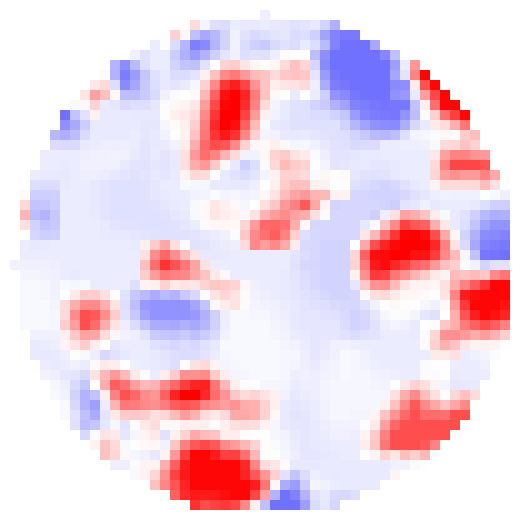

Scala colori: -0.82 — 0.82


In [27]:
masked_roi = np.ma.masked_invalid(
    roi
)

masked_roi = np.ma.masked_where(
    ~circle_mask,
    masked_roi,
)

vmax = np.nanmax(
    np.abs(roi)
)

if vmax == 0 or np.isnan(vmax):
    vmax = 1.0

roi_colormap = mpl.colormaps[
    COLORMAP
].copy()

roi_colormap.set_bad(
    (1.0, 1.0, 1.0, 1.0)
)

plt.figure(
    figsize=(5, 5),
    facecolor="white",
)

plt.imshow(
    masked_roi,
    cmap=roi_colormap,
    vmin=-vmax,
    vmax=vmax,
    interpolation="nearest",
)

plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

print("Scala colori:", -vmax, "—", vmax)


## Cella 6 — Salvataggio PNG


In [29]:
normalizer = mpl.colors.Normalize(
    vmin=-vmax,
    vmax=vmax,
    clip=True,
)

roi_rgba = roi_colormap(
    normalizer(masked_roi)
)

roi_rgb = np.round(
    roi_rgba[:, :, :3] * 255
).astype(np.uint8)

roi_image = Image.fromarray(
    roi_rgb,
    mode="RGB",
)

OUTPUT_PNG.parent.mkdir(
    parents=True,
    exist_ok=True,
)

roi_image.save(
    OUTPUT_PNG,
    format="PNG",
)

print("PNG salvato:", OUTPUT_PNG)
print("Dimensione:", roi_image.size)
print("Modalità:", roi_image.mode)


PNG salvato: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/surfmap/output_SURFMAP_8WDW_UMGSP2_4rev_aligned_2_bfactor/smoothed_matrices/8WDW_UMGSP2_4rev_aligned_bfactor_smoothed_matrix.png
Dimensione: (50, 50)
Modalità: RGB
